# ripple_algo.py 逐步演示
使用 `data/ripple_test_dataset/` 中的 5 張圖片作為連續幀序列，展示 v3 流水線的每一步輸出。

In [1]:
import sys; sys.path.insert(0, '.')
import glob, cv2, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from core.ripple_algo import (
    _preprocess, _specular_mask, _canny_edges, _sobel_gradients,
    _compute_flow_divergence, _find_divergence_peaks,
    _estimate_homography, _update_tracked_centers,
    _radius_bin_peak_edge_score, _radial_expansion_score, _ring_pool_mean,
    _render_candidate_heatmap, _grid_max_pool, _grid_density_pool,
    _soft_saturate,
    RippleDetector, RippleAlgoConfig, activity_level,
)

paths = sorted(glob.glob('data/ripple_test_dataset/*.png'))
cfg = RippleAlgoConfig()

def bgr2rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def flow_to_rgb(flow):
    """Optical flow HSV visualization."""
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])
    hsv = np.zeros((flow.shape[0], flow.shape[1], 3), dtype=np.uint8)
    hsv[..., 0] = ang * 180 / np.pi / 2
    hsv[..., 1] = 255
    hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

print(f'Loaded {len(paths)} frames')

Loaded 5 frames


## 完整流水線 (透過 RippleDetector.process)
逐幀餵入，展示每幀的所有中間結果。

In [2]:
frames_bgr_raw = [cv2.imread(p) for p in paths]
# 所有圖片尺寸必須一致（Optical flow / Homography 要求）
target_size = (640, 480)  # (W, H) — 統一尺寸，原始圖約 900×900 降至此便於演示
frames_bgr = [cv2.resize(f, target_size) for f in frames_bgr_raw]
grays = [_preprocess(f, cfg) for f in frames_bgr]
spec_masks = [_specular_mask(f, cfg) for f in frames_bgr]
edges_list = [_canny_edges(g, cfg) for g in grays]
gxgy = [_sobel_gradients(g) for g in grays]

detector = RippleDetector(cfg)
results = []
for f in frames_bgr:
    r = detector.process(f)
    if r is not None:
        results.append(r)

print(f'Got {len(results)} results (first frame skipped)')
for r in results:
    print(f'  frame {r.frame_index}: peak={r.mid_score.max():.3f}  '
          f'mean={r.mid_score.mean():.3f}  level={activity_level(float(r.mid_score.max()))}  '
          f'candidates={len(r.candidates)}')

Got 4 results (first frame skipped)
  frame 1: peak=0.000  mean=0.000  level=idle  candidates=0
  frame 2: peak=0.000  mean=0.000  level=idle  candidates=0
  frame 3: peak=0.000  mean=0.000  level=idle  candidates=0
  frame 4: peak=0.147  mean=0.007  level=idle  candidates=1


---
### Step 0: 原圖 (Original)
原始 BGR 輸入，來自 `data/ripple_test_dataset/`。

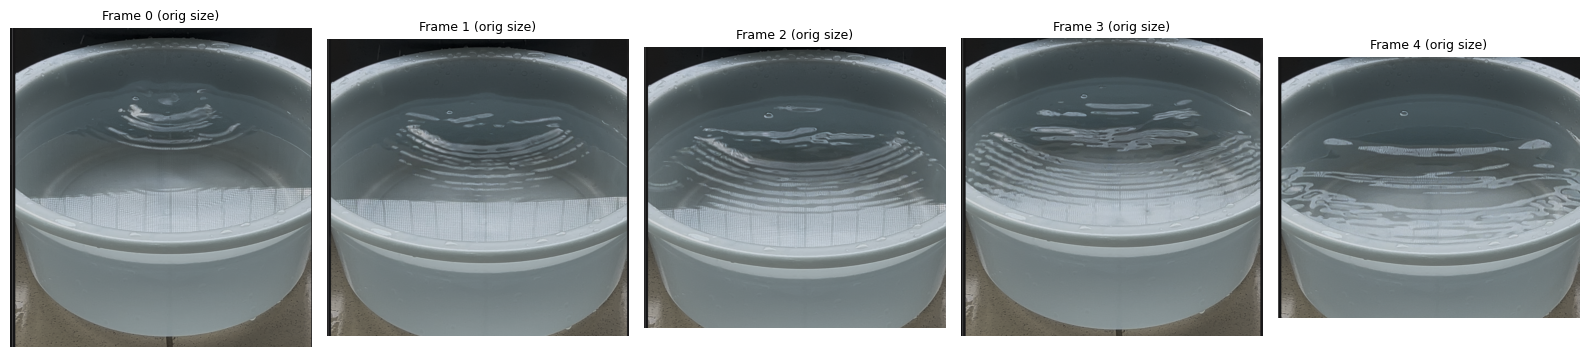

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for i, f in enumerate(frames_bgr_raw):
    axes[i].imshow(bgr2rgb(f))
    axes[i].set_title(f'Frame {i} (orig size)', fontsize=9)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

---
### Step 1: Preprocess (灰度 + CLAHE + 模糊)
`gray → CLAHE(clip=3.0, tile=8×8) → GaussianBlur(3×3)`
先讓 CLAHE 看到原始高頻訊號，再輕度平滑。

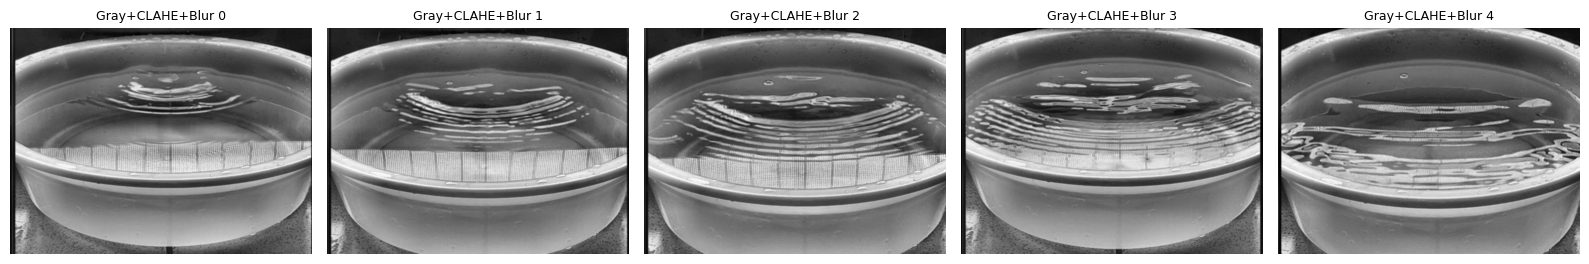

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for i, g in enumerate(grays):
    axes[i].imshow(g, cmap='gray')
    axes[i].set_title(f'Gray+CLAHE+Blur {i}', fontsize=9)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

---
### Step 2: Specular Mask (高光遮罩)
`HSV: V ≥ 220 AND S ≤ 50 → 高光點 → dilate(5)`
水面反射亮點標記為無效 (白色=高光)，後續所有計算忽略這些區域。

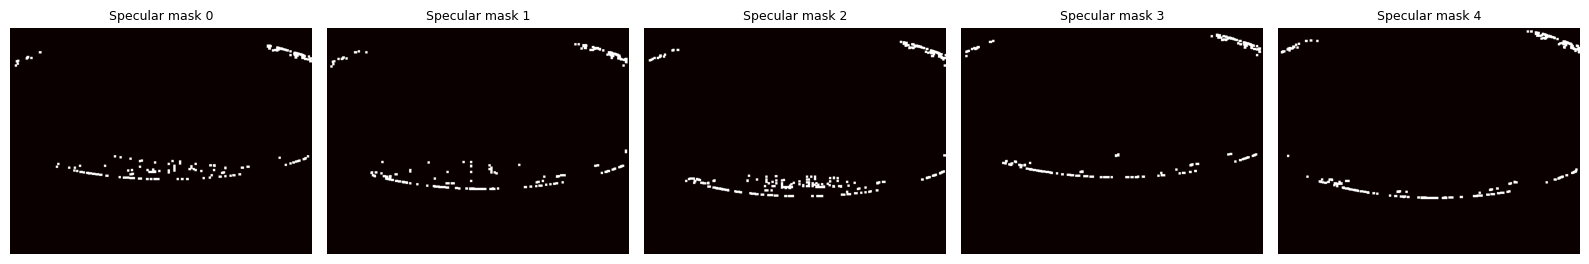

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for i, sm in enumerate(spec_masks):
    axes[i].imshow(sm, cmap='hot')
    axes[i].set_title(f'Specular mask {i}', fontsize=9)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

---
### Step 3: Canny 邊緣
`cv2.Canny(low=15, high=60)` — 低閾值故意設低以捕捉微弱波紋邊緣，噪聲由後續的 radius-bin 評分 + structure gate 壓制。

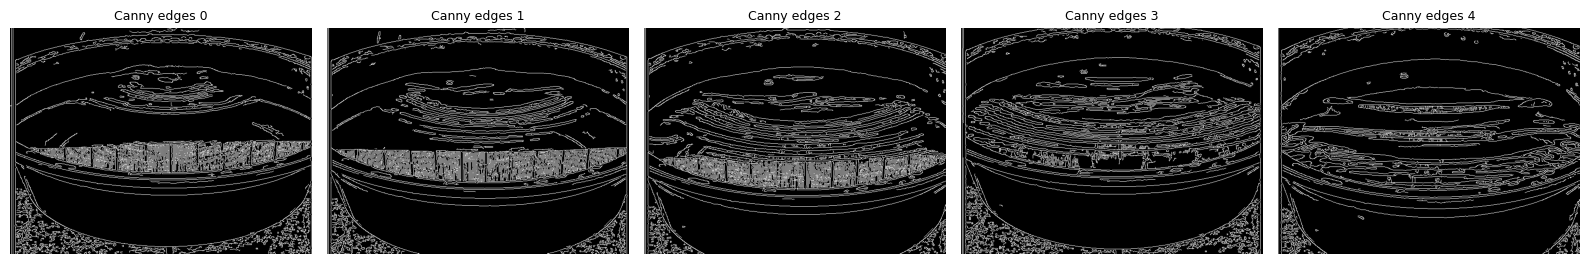

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for i, e in enumerate(edges_list):
    axes[i].imshow(e, cmap='gray')
    axes[i].set_title(f'Canny edges {i}', fontsize=9)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

---
### Step 3b: Sobel 梯度 (Gx, Gy)
用於後續徑向邊緣對齊度評分 (`_radius_bin_peak_edge_score`)。

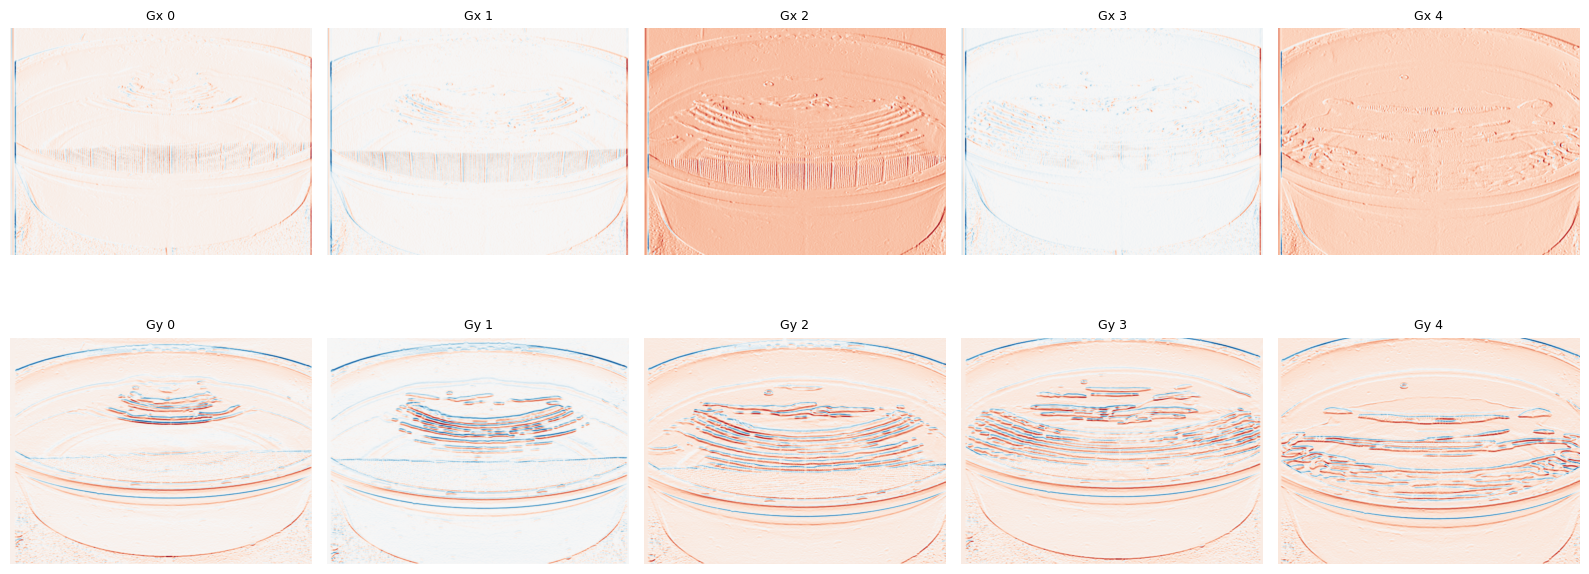

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for i, (gx, gy) in enumerate(gxgy):
    axes[0, i].imshow(gx, cmap='RdBu')
    axes[0, i].set_title(f'Gx {i}', fontsize=9)
    axes[0, i].axis('off')
    axes[1, i].imshow(gy, cmap='RdBu')
    axes[1, i].set_title(f'Gy {i}', fontsize=9)
    axes[1, i].axis('off')
plt.tight_layout()
plt.show()

---
### Step 4: MOG2 背景減除 (soft_fg)
`soft_fg = 0.3 + 0.7 × (fg/255)` — 背景像素保留 30% 權重，前 4 幀展示 MOG2 模型的適應過程。

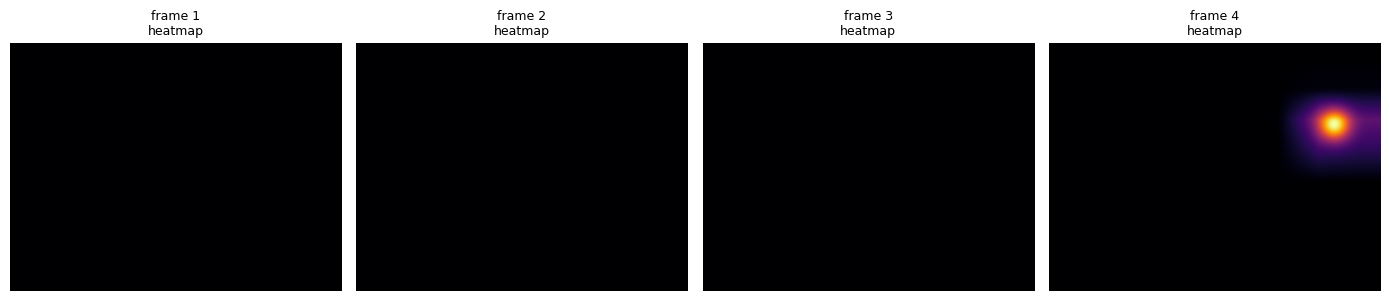

frame 1: candidates=[]
frame 2: candidates=[]
frame 3: candidates=[]
frame 4: candidates=[(550, 159, 0.6780194520950318)]


In [8]:
det2 = RippleDetector(cfg)
mog2_results = []
for f in frames_bgr:
    r = det2.process(f)
    if r is not None:
        mog2_results.append(r)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for i, r in enumerate(mog2_results):
    axes[i].imshow(r.heatmap, cmap='inferno')
    axes[i].set_title(f'frame {r.frame_index}\nheatmap', fontsize=9)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

for r in mog2_results:
    print(f'frame {r.frame_index}: candidates={r.candidates}')

---
### Step 5: Camera Motion Compensation (Homography)
KLT 角點追蹤 → RANSAC 估計 Homography H → 將上一幀 gray/edges 映射到當前坐標系。
只有對齊後的幀才用於 optial flow 和 inter-frame 比較。

In [9]:
for fi in range(len(grays)-1):
    prev, cur = grays[fi], grays[fi+1]
    H = _estimate_homography(prev, cur, cfg)
    print(f'Homography frame {fi}→{fi+1}: '
          f'{"estimated" if H is not None else "skipped (too small / unreliable)"}')
    if H is not None:
        print(f'  H =\n{H}')

Homography frame 0→1: estimated
  H =
[[ 1.00024567e+00  7.13236433e-04 -2.88514107e+00]
 [ 4.80748361e-04  1.07675292e+00 -4.34222653e+00]
 [ 1.21426238e-06  3.43347381e-07  1.00000000e+00]]
Homography frame 1→2: estimated
  H =
[[ 1.11535801e+00  7.68882503e-02 -3.50324618e+01]
 [ 2.09872871e-02  1.16197764e+00 -2.38438070e+01]
 [ 7.24089364e-05  1.20484263e-04  1.00000000e+00]]
Homography frame 2→3: estimated
  H =
[[ 1.03348101e+00 -2.50053493e-03  9.72340682e-01]
 [ 1.19757196e-02  9.02729567e-01 -1.20993373e+01]
 [ 2.22687931e-04 -5.97121226e-05  1.00000000e+00]]
Homography frame 3→4: skipped (too small / unreliable)


---
### Step 6: Optical Flow (DIS FAST) + Divergence
光流在 `flow_scale=0.5` 降採樣圖上計算，再放大回原尺寸。散度 `div = ∂u/∂x + ∂v/∂y` 只取正部。
平滑後的散度場 (`div_smooth`) 用於找候選漣漪中心。

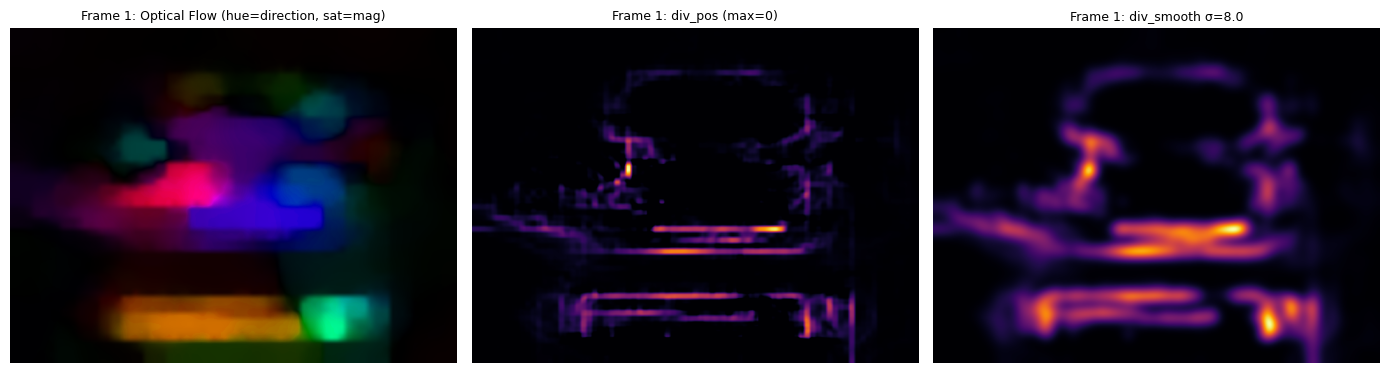

  Frame 1: divergence peaks = [(429, 288, 5.7632), (481, 423, 5.7138), (223, 203, 5.1226), (298, 319, 4.6684), (161, 409, 4.2625), (359, 293, 4.2281), (513, 401, 4.1392), (226, 164, 3.8707), (284, 384, 3.842), (400, 317, 3.1524), (412, 319, 3.1285), (275, 288, 3.1083), (349, 383, 3.0614), (542, 404, 2.9634), (243, 407, 2.9351), (108, 287, 2.9207)]


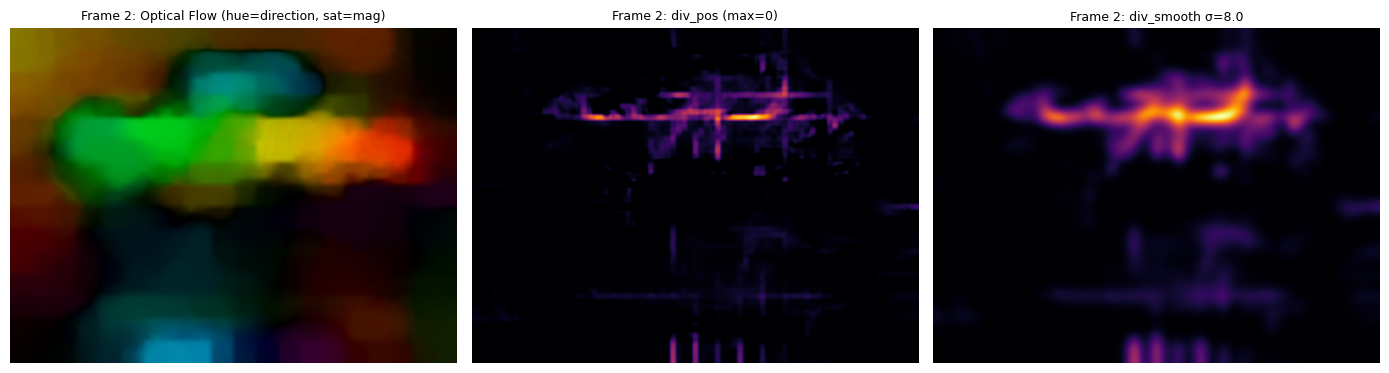

  Frame 2: divergence peaks = [(412, 126, 7.6844), (350, 124, 7.2506), (312, 120, 5.9791), (443, 96, 5.7216), (176, 127, 5.1263), (233, 123, 4.0742), (351, 170, 3.5853), (518, 133, 3.4699), (288, 479, 3.3099), (469, 131, 3.1068), (320, 468, 2.5996), (322, 167, 2.3967), (383, 479, 2.0269), (122, 116, 1.7672), (416, 50, 1.7009), (413, 382, 1.5453)]


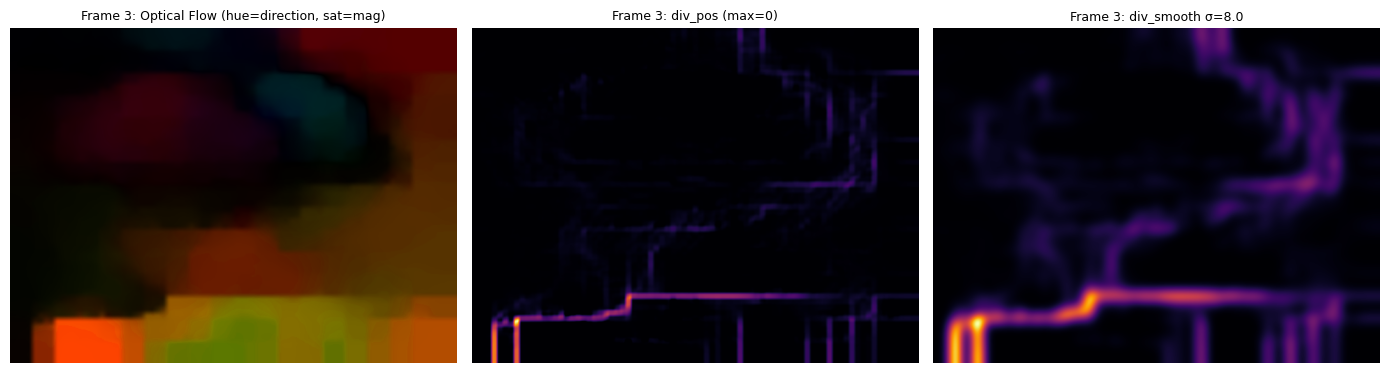

  Frame 3: divergence peaks = [(63, 423, 30.775), (32, 479, 27.0278), (224, 391, 25.4824), (64, 479, 24.4666), (195, 409, 19.1914), (354, 384, 16.8142), (124, 414, 12.1182), (535, 222, 10.8305), (151, 415, 10.5211), (544, 421, 9.5988), (572, 407, 9.54), (511, 459, 9.1818), (384, 7, 9.031), (413, 5, 8.6927), (383, 479, 8.6694), (513, 130, 8.2244)]


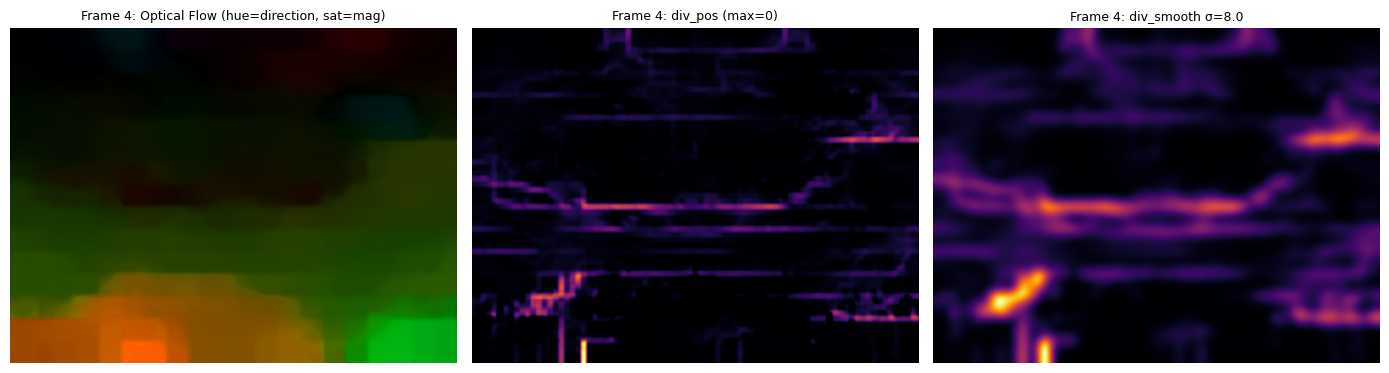

  Frame 4: divergence peaks = [(159, 471, 14.9114), (96, 392, 14.8188), (127, 379, 13.2743), (149, 359, 12.5296), (581, 158, 10.4865), (165, 256, 10.339), (550, 159, 9.5653), (403, 256, 8.7384), (248, 257, 8.653), (211, 256, 7.9605), (566, 413, 7.6043), (639, 414, 7.5457), (639, 159, 7.3457), (597, 414, 6.883), (128, 472, 6.779), (527, 410, 6.6898)]


In [10]:
det3 = RippleDetector(cfg)
det3.process(frames_bgr[0])  # init first frame

for fi in range(1, len(frames_bgr)):
    gray = grays[fi]
    prev_gray = grays[fi-1]
    H = _estimate_homography(prev_gray, gray, cfg)
    if H is not None:
        prev_aligned = cv2.warpPerspective(prev_gray, H, (gray.shape[1], gray.shape[0]))
    else:
        prev_aligned = prev_gray
    flow = det3._optical_flow(prev_aligned, gray)
    div_pos = _compute_flow_divergence(flow)
    
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].imshow(flow_to_rgb(flow))
    axes[0].set_title(f'Frame {fi}: Optical Flow (hue=direction, sat=mag)', fontsize=9)
    axes[0].axis('off')
    axes[1].imshow(div_pos, cmap='inferno')
    axes[1].set_title(f'Frame {fi}: div_pos (max=0)', fontsize=9)
    axes[1].axis('off')
    div_smooth = cv2.GaussianBlur(div_pos, (0, 0), cfg.div_peak_sigma)
    axes[2].imshow(div_smooth, cmap='inferno')
    axes[2].set_title(f'Frame {fi}: div_smooth σ={cfg.div_peak_sigma}', fontsize=9)
    axes[2].axis('off')
    plt.tight_layout()
    plt.show()
    
    peaks = _find_divergence_peaks(div_smooth, cfg)
    print(f'  Frame {fi}: divergence peaks = {[(cx, cy, round(v, 4)) for cx, cy, v in peaks]}')

---
### Step 6 extra: Optical Flow + Divergence on Sobel Edge Maps
將 preprocess 後的灰度圖先轉 Sobel magnitude `|g| = sqrt(gx² + gy²)` 作為光流的輸入，
以此測試邊緣強化是否能降低噪聲、改善散度場品質。
上下兩排對比：原始灰度光流 vs. Sobel 邊緣光流。

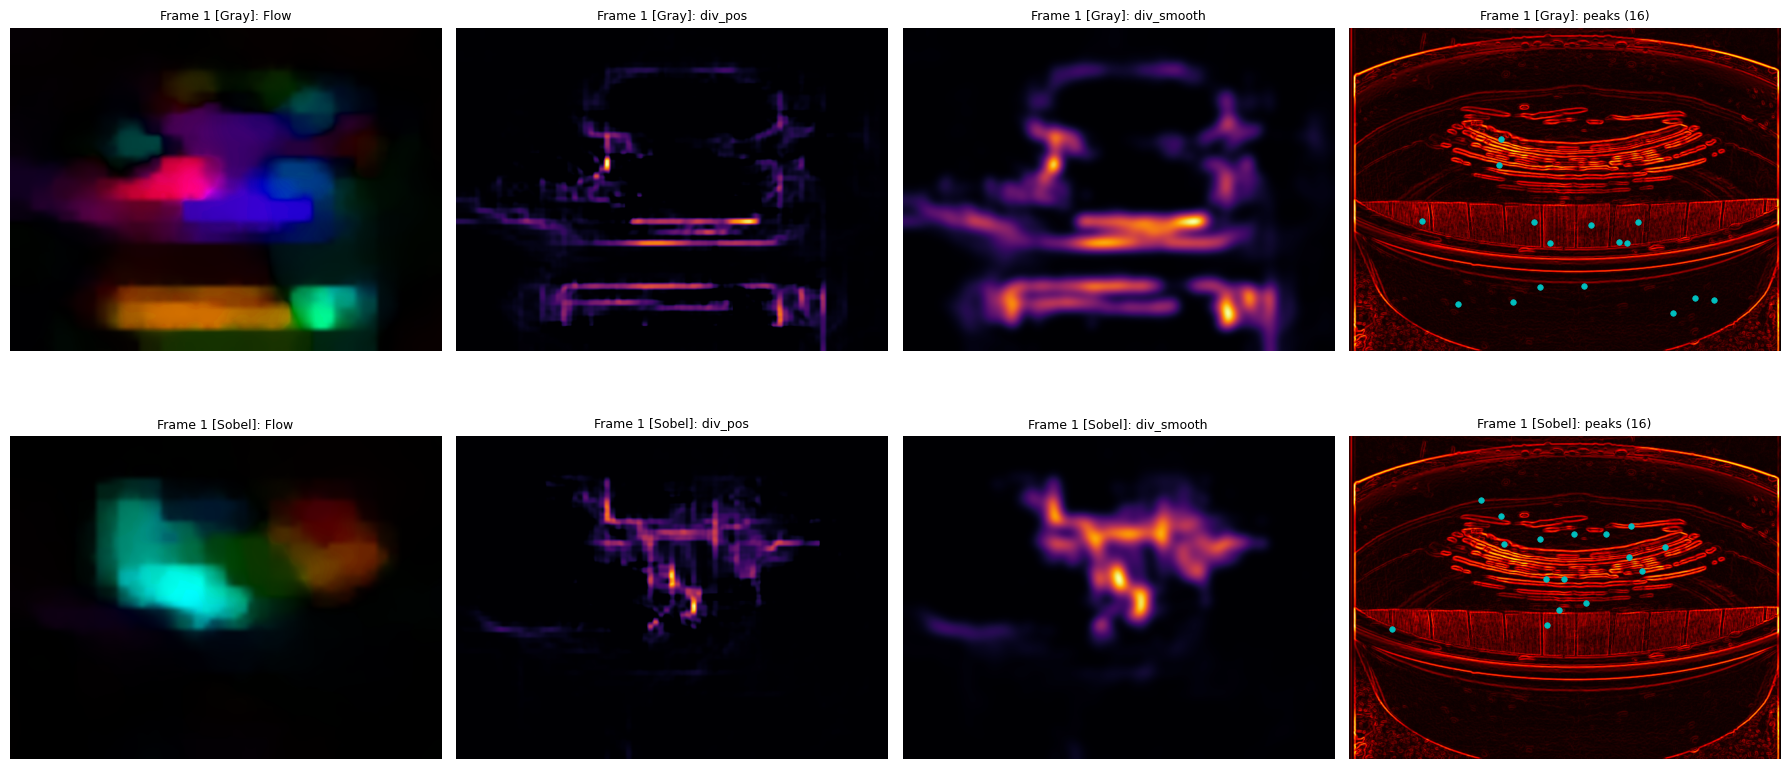

  Frame 1: Gray peaks=16, Sobel peaks=16
    Sobel peaks = [(319, 212, 11.33), (352, 248, 10.49), (382, 145, 9.2), (284, 153, 9.12), (225, 119, 8.86), (334, 146, 8.71), (469, 165, 6.99), (292, 212, 6.45), (435, 200, 6.22), (230, 161, 6.03), (419, 133, 5.63), (416, 179, 5.53), (293, 281, 4.43), (196, 95, 3.04), (311, 258, 2.28), (63, 286, 2.08)]


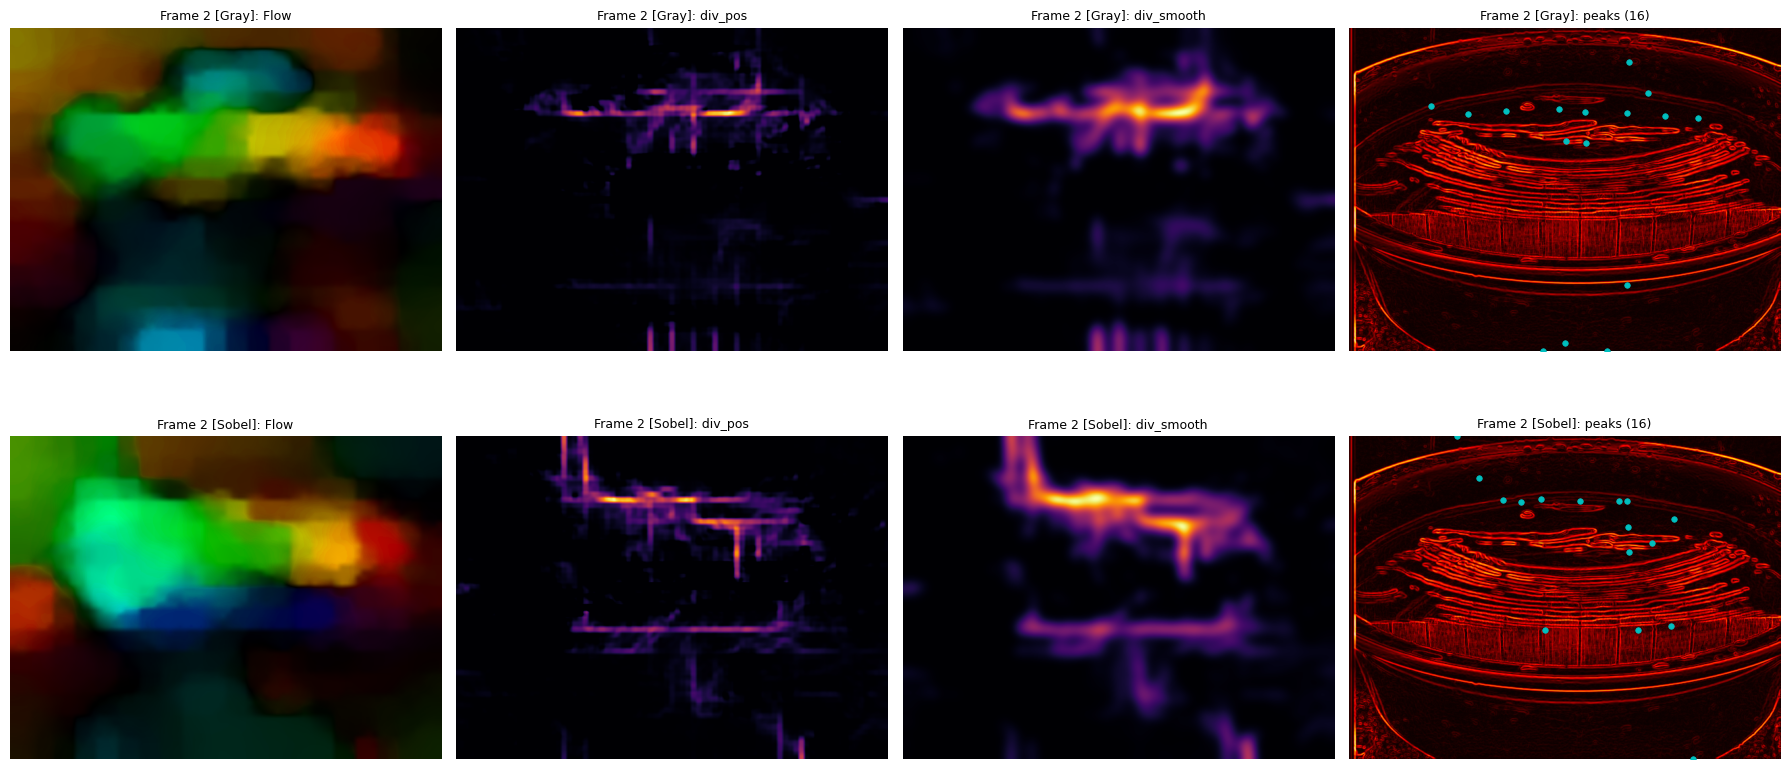

  Frame 2: Gray peaks=16, Sobel peaks=16
    Sobel peaks = [(285, 94, 7.29), (414, 135, 7.18), (255, 98, 7.14), (229, 95, 6.97), (342, 97, 6.44), (193, 62, 5.54), (416, 173, 4.59), (160, 0, 3.95), (291, 288, 3.49), (511, 479, 3.42), (482, 124, 3.35), (477, 282, 3.0), (450, 159, 2.97), (401, 96, 2.95), (412, 96, 2.95), (429, 288, 2.92)]


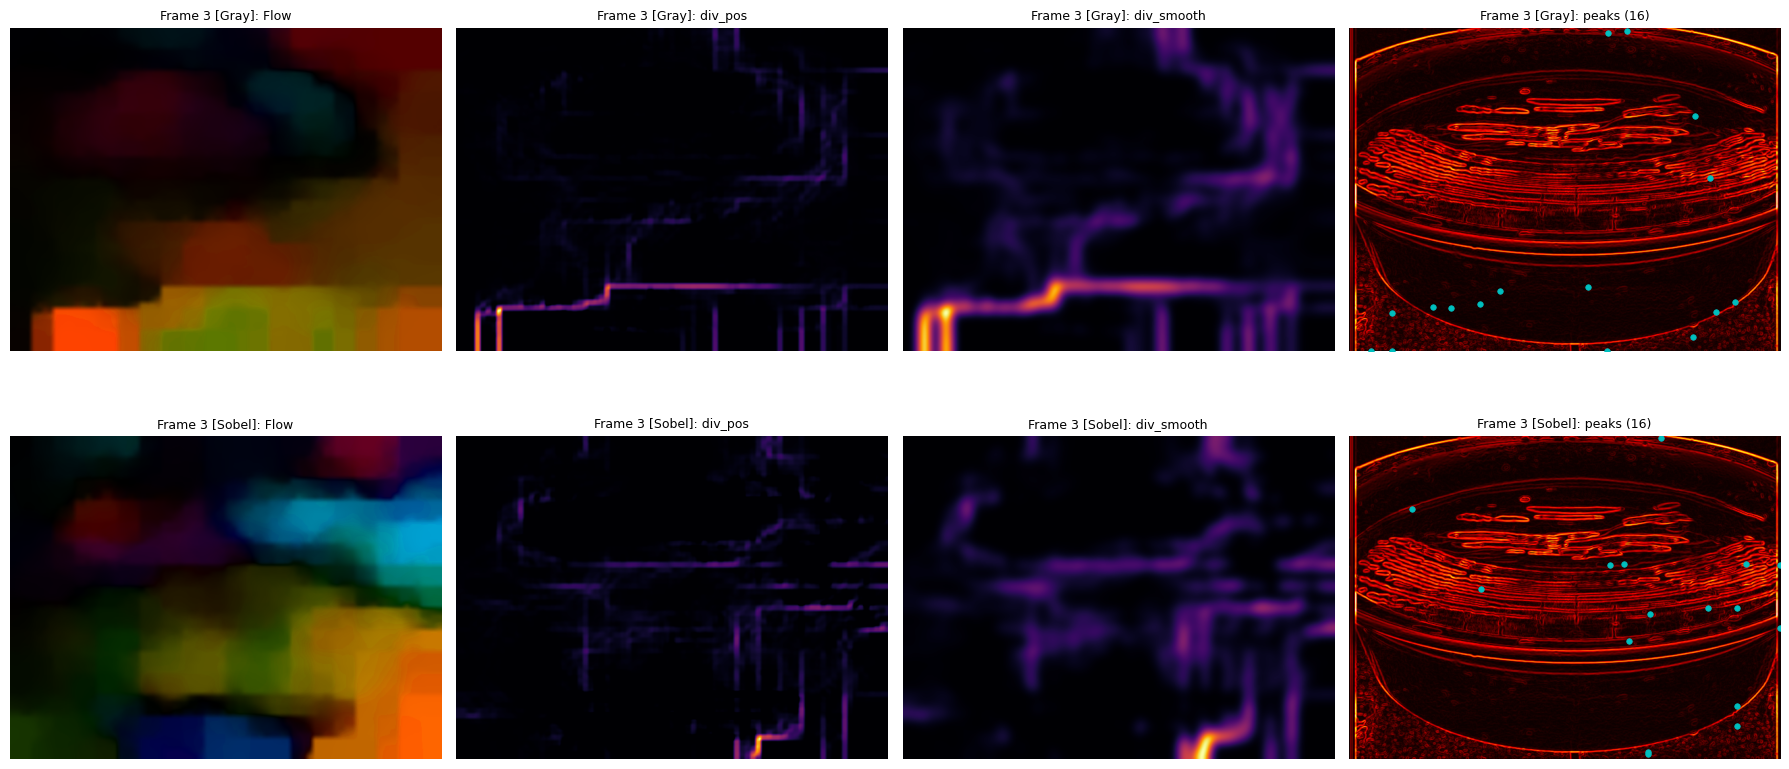

  Frame 3: Gray peaks=16, Sobel peaks=16
    Sobel peaks = [(443, 472, 17.03), (444, 469, 17.02), (532, 256, 6.51), (639, 285, 6.23), (415, 304, 5.88), (463, 3, 5.67), (639, 191, 5.01), (576, 401, 4.91), (94, 109, 4.87), (589, 190, 4.73), (576, 255, 4.69), (446, 265, 4.68), (575, 430, 4.64), (196, 227, 4.61), (408, 190, 4.44), (387, 192, 4.25)]


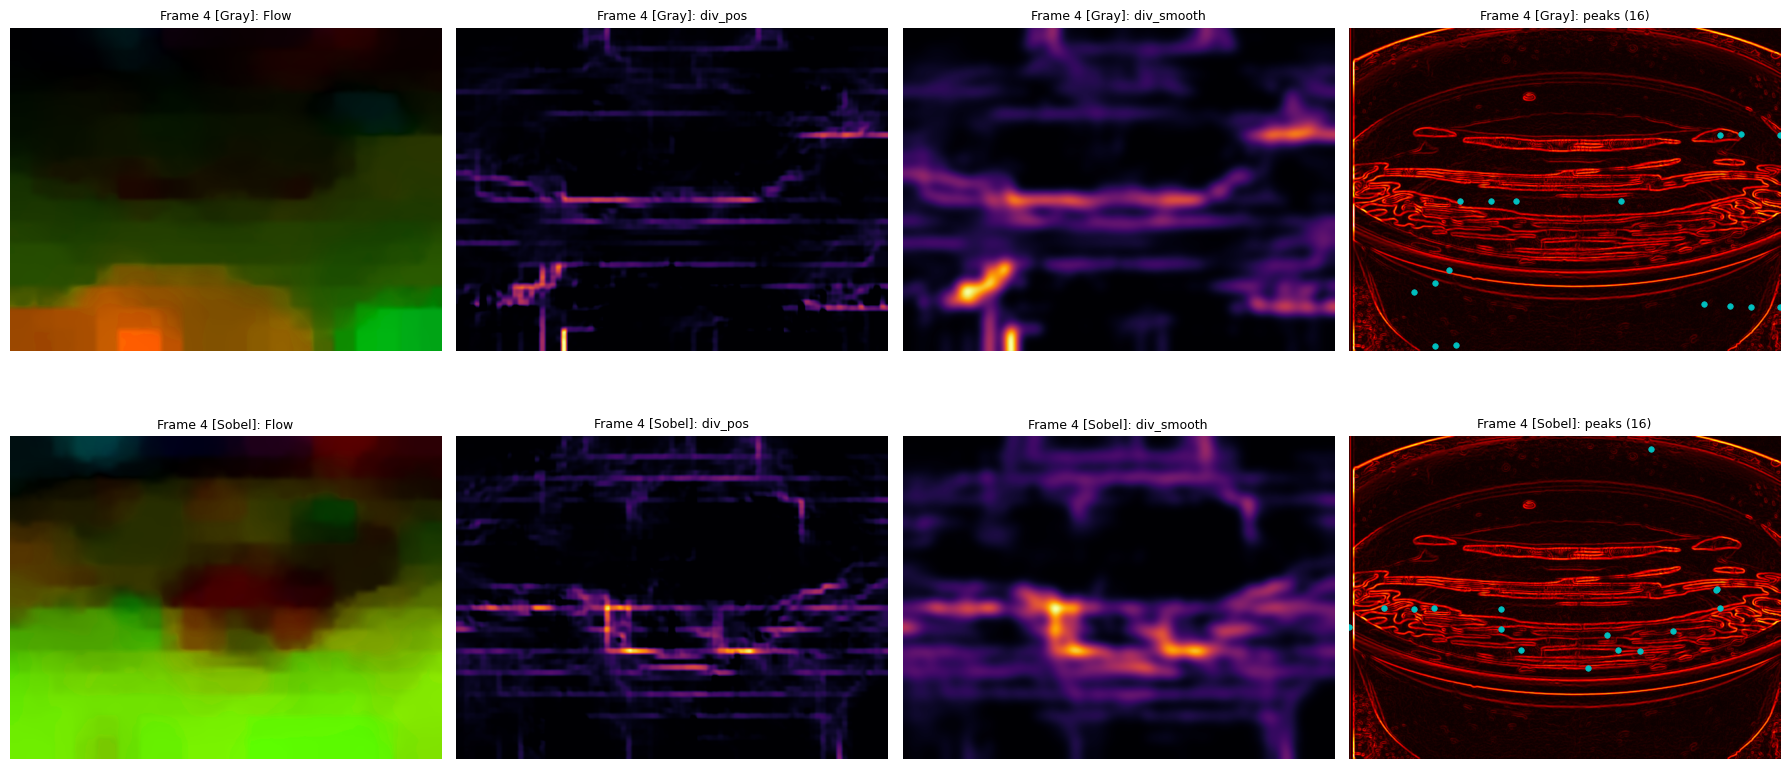

  Frame 4: Gray peaks=16, Sobel peaks=16
    Sobel peaks = [(226, 257, 10.79), (255, 318, 9.55), (432, 319, 9.21), (226, 287, 8.62), (399, 318, 8.61), (383, 296, 6.54), (126, 256, 6.33), (354, 344, 6.13), (97, 257, 5.92), (52, 256, 5.48), (480, 290, 5.31), (0, 284, 5.19), (551, 255, 4.88), (544, 228, 4.75), (546, 227, 4.75), (448, 20, 4.34)]


In [11]:
det4 = RippleDetector(cfg)
det4.process(frames_bgr[0])

# 預先計算每幀的 Sobel magnitude（歸一化到 uint8 供 DIS 使用）
sobel_mag_list = []
for g in grays:
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    mag = np.sqrt(gx * gx + gy * gy)
    mag_u8 = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    sobel_mag_list.append(mag_u8)

for fi in range(1, len(frames_bgr)):
    gray = grays[fi]
    prev_gray = grays[fi - 1]
    sobel_cur = sobel_mag_list[fi]
    sobel_prev = sobel_mag_list[fi - 1]

    H = _estimate_homography(prev_gray, gray, cfg)
    if H is not None:
        prev_aligned = cv2.warpPerspective(prev_gray, H, (gray.shape[1], gray.shape[0]))
        sobel_prev_aligned = cv2.warpPerspective(sobel_prev, H, (gray.shape[1], gray.shape[0]),
                                                  flags=cv2.INTER_LINEAR)
    else:
        prev_aligned = prev_gray
        sobel_prev_aligned = sobel_prev

    # A. 原始灰度光流 (對照組)
    flow_gray = det4._optical_flow(prev_aligned, gray)
    div_gray = _compute_flow_divergence(flow_gray)
    div_gray_smooth = cv2.GaussianBlur(div_gray, (0, 0), cfg.div_peak_sigma)
    peaks_gray = _find_divergence_peaks(div_gray_smooth, cfg)

    # B. Sobel 邊緣光流 (實驗組)
    flow_sobel = det4._optical_flow(sobel_prev_aligned, sobel_cur)
    div_sobel = _compute_flow_divergence(flow_sobel)
    div_sobel_smooth = cv2.GaussianBlur(div_sobel, (0, 0), cfg.div_peak_sigma)
    peaks_sobel = _find_divergence_peaks(div_sobel_smooth, cfg)

    # 視覺化：上排 = 灰度, 下排 = Sobel
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    for ax_row, label, flow, div, div_smooth, peaks in [
        (0, 'Gray', flow_gray, div_gray, div_gray_smooth, peaks_gray),
        (1, 'Sobel', flow_sobel, div_sobel, div_sobel_smooth, peaks_sobel),
    ]:
        axes[ax_row, 0].imshow(flow_to_rgb(flow))
        axes[ax_row, 0].set_title(f'Frame {fi} [{label}]: Flow', fontsize=9)
        axes[ax_row, 0].axis('off')
        axes[ax_row, 1].imshow(div, cmap='inferno')
        axes[ax_row, 1].set_title(f'Frame {fi} [{label}]: div_pos', fontsize=9)
        axes[ax_row, 1].axis('off')
        axes[ax_row, 2].imshow(div_smooth, cmap='inferno')
        axes[ax_row, 2].set_title(f'Frame {fi} [{label}]: div_smooth', fontsize=9)
        axes[ax_row, 2].axis('off')
        # 把 peaks 畫在 Sobel edge map 上
        axes[ax_row, 3].imshow(sobel_cur, cmap='hot')
        for cx, cy, _ in peaks:
            axes[ax_row, 3].plot(cx, cy, 'co', markersize=4, markeredgewidth=0.5)
        axes[ax_row, 3].set_title(f'Frame {fi} [{label}]: peaks ({len(peaks)})', fontsize=9)
        axes[ax_row, 3].axis('off')

    plt.tight_layout()
    plt.show()

    print(f'  Frame {fi}: Gray peaks={len(peaks_gray)}, Sobel peaks={len(peaks_sobel)}')
    if peaks_sobel:
        print(f'    Sobel peaks = {[(cx, cy, round(v, 2)) for cx, cy, v in peaks_sobel]}')

---
### Step 7: 最終結果 (最後一幀完整輸出)
展示 `RippleDetector` 對所有 5 幀的最終輸出：heatmap, mid_score grid, candidates。

In [ ]:
if results:
    last = results[-1]
    
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    
    # 1. Heatmap overlaid on original
    overlay = cv2.applyColorMap((last.heatmap * 255).astype(np.uint8), cfg.heatmap_colormap)
    vis = cv2.addWeighted(frames_bgr[-1], 0.5, overlay, 0.5, 0)
    axes[0].imshow(bgr2rgb(vis))
    for cx, cy, _ in last.candidates:
        axes[0].add_patch(Circle((cx, cy), 6, fill=False, ec='white', lw=1.5))
    axes[0].set_title(f'Frame {last.frame_index}: Heatmap + Candidates', fontsize=9)
    axes[0].axis('off')
    
    # 2. mid_score grid
    im = axes[1].imshow(last.mid_score, cmap='inferno', vmin=0, vmax=1)
    axes[1].set_title(f'Frame {last.frame_index}: mid_score {cfg.grid_rows}×{cfg.grid_cols}', fontsize=9)
    for r in range(cfg.grid_rows):
        for c in range(cfg.grid_cols):
            axes[1].text(c, r, f'{last.mid_score[r,c]:.2f}', ha='center', va='center',
                        fontsize=6, color='w' if last.mid_score[r,c] > 0.4 else 'k')
    plt.colorbar(im, ax=axes[1])
    
    # 3. raw_score grid
    im2 = axes[2].imshow(last.raw_score, cmap='inferno', vmin=0, vmax=1)
    axes[2].set_title(f'Frame {last.frame_index}: raw_score {cfg.grid_rows}×{cfg.grid_cols}', fontsize=9)
    for r in range(cfg.grid_rows):
        for c in range(cfg.grid_cols):
            axes[2].text(c, r, f'{last.raw_score[r,c]:.2f}', ha='center', va='center',
                        fontsize=6, color='w' if last.raw_score[r,c] > 0.4 else 'k')
    plt.colorbar(im2, ax=axes[2])
    
    plt.tight_layout()
    plt.show()
    
    print(f'\n=== Frame {last.frame_index} Summary ===')
    print(f'  Level: {activity_level(float(last.mid_score.max()))}')
    print(f'  Peak mid_score: {last.mid_score.max():.4f}')
    print(f'  Mean mid_score: {last.mid_score.mean():.4f}')
    print(f'  Candidates ({len(last.candidates)}):')
    for cx, cy, score in last.candidates:
        print(f'    ({cx:3d}, {cy:3d})  structure={score:.4f}')
    print(f'\n  Sliding window scores:')
    print(f'    short  mean: {last.short_score.mean():.4f}')
    print(f'    mid    mean: {last.mid_score.mean():.4f}')
    print(f'    long   mean: {last.long_score.mean():.4f}')


---
## 流水線總結

```
┌─────────────┐    ┌─────────────┐    ┌────────────────────┐
│  Preprocess │───→│ Specular    │───→│ MOG2 (soft_fg)     │
│ gray+CLAHE  │    │ mask (HSV)  │    │ bg_soft_floor=0.3  │
│ +blur(3)    │    │             │    │                    │
└─────────────┘    └─────────────┘    └────────┬───────────┘
                                               │
                    ┌──────────────────────────┤
                    ▼                          ▼
            ┌─────────────┐           ┌────────────────┐
            │ Canny edges │           │ valid_mask     │
            │ low=15      │           │ (~specular)    │
            │ high=60     │           └────────┬───────┘
            └──────┬──────┘                    │
                   │                           │
    ┌──────────────┴──────────────┐            │
    ▼                             ▼            ▼
┌──────────┐              ┌────────────┐  ┌──────────┐
│ Homography│              │ KLT+RANSAC│  │ soft_fg  │
│ warp prev│◄─────────────│ H matrix  │  │ * valid  │
│ gray/edges│              └────────────┘  └──────────┘
└────┬─────┘
     │
     ├────→ Optical Flow (DIS FAST on aligned frames)
     │         │
     │         ├──→ div_pos = max(∂u/∂x + ∂v/∂y, 0)
     │         │         │
     │         │         ├──→ GaussianBlur(σ=8) → div_smooth
     │         │         │         │
     │         │         │         └──→ FIND DIVERGENCE PEAKS
     │         │         │              (local max + threshold + top-N)
     │         │         │
     │         │         ├──→ radius_bin_peak_edge_score
     │         │         │    (top-k radius bands radial alignment)
     │         │         │
     │         │         └──→ radial_expansion_score
     │         │              (outward flow projection on ring)
     │         │
     │         └──→ div_ring (mean divergence in ring)
     │
     ├────→ diff + edge_xor (on aligned frames, gated by soft_fg)
     │         │
     │         ├──→ motion_field → grid_density → soft_saturate → activity_grid
     │         └──→ edge_field   → grid_density → soft_saturate ─┘
     │
     └────→ TEMPORAL TRACKING
            greedy NN matching → stable ≥ 3 frames
                    │
                    ▼
            ┌───────────────┐
            │ PER-CANDIDATE │
            │   SCORING     │
            │               │
            │ spatial  = f(radius_bin_peak, edges, gx, gy)
            │ expansion= f(radial_flow, div_ring)
            │ structure= w_s*spatial + w_e*expansion
            └───────┬───────┘
                    │
                    ▼
            ┌──────────────────────┐
            │ Gaussian blob render │
            │ → structure_heatmap  │
            └──────────┬───────────┘
                       │
            ┌──────────┴───────────┐
            ▼                      ▼
     grid_max_pool          grid_density_pool
     → structure_grid       → motion/edge density
            │                      │
            │                  soft_saturate
            │                  → activity_grid
            │                      │
            └──────┬───────────────┘
                   │
                   ▼
         raw_score = activity_grid × structure_grid
                   │
         ┌─────────┴─────────┐
         ▼                   ▼
   sliding windows     final heatmap
   (short/mid/long)    (mid_full + struct_smooth)
```